### lan.ipynb — Đọc dữ liệu, làm sạch và khám phá (EDA)

## Bài tập lớn Khai thác dữ liệu: Dry Bean Dataset 

### Nội dung thực hiện

1. Đọc dữ liệu Excel, chuyển sang CSV và kiểm tra tính toàn vẹn.
2. Khảo sát cấu trúc và thống kê mô tả dữ liệu.
3. Kiểm tra giá trị thiếu, bản ghi trùng và ngoại lệ IQR.
4. Trực quan hóa phân bố lớp, histogram, boxplot và tương quan Pearson.
5. Tổng hợp kết quả EDA và đề xuất cho các bước phân tích tiếp theo.

**Phạm vi:** Tập trung vào đọc, kiểm tra và khám phá dữ liệu; không thực hiện huấn luyện mô hình.


## 0. Thiết lập thư mục và môi trường

Khởi tạo các thư viện cần thiết và xác định đường dẫn đến thư mục dữ liệu gốc, dữ liệu xử lý, bảng thống kê và biểu đồ.

File Excel đầu vào được đặt tại `data/raw/`. Các kết quả phân tích được lưu trong `outputs/tables/` và `outputs/figures/` để phục vụ tổng hợp báo cáo.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Xác định thư mục gốc của dự án
ROOT = Path.cwd()

if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent

RAW_DIR = ROOT / "data" / "raw"
PROCESSED_DIR = ROOT / "data" / "processed"
FIGURES_DIR = ROOT / "outputs" / "figures"
TABLES_DIR = ROOT / "outputs" / "tables"

# Tạo các thư mục lưu kết quả
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

print("Thư mục dự án:", ROOT)
print("Thư mục dữ liệu gốc:", RAW_DIR)
print("Thư mục dữ liệu xử lý:", PROCESSED_DIR)
print("Thư mục biểu đồ:", FIGURES_DIR)
print("Thư mục bảng:", TABLES_DIR)


Thư mục dự án: d:\DEEP\Khai_Thac_Du_Lieu_Gr6
Thư mục dữ liệu gốc: d:\DEEP\Khai_Thac_Du_Lieu_Gr6\data\raw
Thư mục dữ liệu xử lý: d:\DEEP\Khai_Thac_Du_Lieu_Gr6\data\processed
Thư mục biểu đồ: d:\DEEP\Khai_Thac_Du_Lieu_Gr6\outputs\figures
Thư mục bảng: d:\DEEP\Khai_Thac_Du_Lieu_Gr6\outputs\tables


## 01. Đọc dữ liệu gốc

### Mục tiêu
Đọc bộ dữ liệu Dry Bean từ file Excel do nhóm cung cấp, chuyển sang định dạng CSV và kiểm tra tính toàn vẹn của dữ liệu sau chuyển đổi.

### Phương pháp
Sử dụng thư viện Pandas để đọc sheet `Dry_Beans_Dataset`, xuất dữ liệu sang CSV và đọc lại để đối chiếu kích thước, tên cột, kiểu dữ liệu, nhãn `Class` và các giá trị.

Quá trình chuyển đổi không thực hiện loại bỏ bản ghi, thay đổi nhãn hoặc biến đổi đặc trưng.


In [2]:
# DATA-01: Đọc dữ liệu Excel gốc
excel_path = RAW_DIR / "D03 - Dry_Bean_Dataset.xlsx"

assert excel_path.exists(), f"Không tìm thấy file: {excel_path}"

df_excel = pd.read_excel(
    excel_path,
    sheet_name="Dry_Beans_Dataset"
)

print("Kích thước Excel:", df_excel.shape)
display(df_excel.head())

# Chuyển dữ liệu sang CSV
csv_path = PROCESSED_DIR / "dry_bean.csv"

df_excel.to_csv(
    csv_path,
    index=False,
    encoding="utf-8-sig"
)

# Đọc lại CSV để kiểm tra
df = pd.read_csv(csv_path)

checks = {
    "Kích thước": df_excel.shape == df.shape,
    "Tên và thứ tự cột": df_excel.columns.equals(df.columns),
    "Kiểu dữ liệu": df_excel.dtypes.equals(df.dtypes),
    "Nhãn Class": df_excel["Class"].equals(df["Class"])
}

try:
    pd.testing.assert_frame_equal(
        df_excel,
        df,
        check_exact=False,
        rtol=1e-12,
        atol=1e-12
    )
    checks["Giá trị toàn bảng"] = True
except AssertionError:
    checks["Giá trị toàn bảng"] = False

validation = pd.DataFrame({
    "Tiêu chí": list(checks.keys()),
    "Kết quả": [
        "PASS" if value else "FAIL"
        for value in checks.values()
    ]
})

display(validation)

assert all(checks.values()), "Dữ liệu CSV chưa đạt kiểm tra."

print("DATA-01 hoàn thành!")
print("File CSV:", csv_path)


Kích thước Excel: (13611, 17)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


,Tiêu chí,Kết quả
0,Kích thước,PASS
1,Tên và thứ tự cột,PASS
2,Kiểu dữ liệu,PASS
3,Nhãn Class,PASS
4,Giá trị toàn bảng,PASS


DATA-01 hoàn thành!
File CSV: d:\DEEP\Khai_Thac_Du_Lieu_Gr6\data\processed\dry_bean.csv


### Kết quả và nhận xét

Bộ dữ liệu Dry Bean được đọc thành công từ file Excel gốc, gồm **13.611 mẫu và 17 thuộc tính**, trong đó có 16 đặc trưng hình thái và một nhãn phân lớp `Class`.

Dữ liệu được chuyển sang định dạng CSV và kiểm tra tính toàn vẹn. Khi tất cả tiêu chí trong bảng đối chiếu đạt `PASS`, có thể kết luận quá trình chuyển đổi giữ nguyên cấu trúc, nhãn và giá trị dữ liệu trong phạm vi dung sai kiểm tra.

**Hạn chế:** Phép đối chiếu số thực sử dụng dung sai nhỏ, không phải so sánh tuyệt đối từng byte giữa hai định dạng tệp.


## 02. Mô tả thống kê

### Mục tiêu
Khảo sát cấu trúc bộ dữ liệu, phân bố của 7 lớp hạt đậu và các thống kê cơ bản của 16 đặc trưng hình thái.

### Phương pháp
- Sử dụng `shape`, `head()`, `info()` và `dtypes` để khảo sát dữ liệu.
- Sử dụng `value_counts()` để thống kê số mẫu và tỷ lệ từng lớp.
- Tính Min, Max và Mean cho các đặc trưng số bằng Pandas.

Nhãn `Class` được tách khỏi tập đặc trưng và không tham gia các phép thống kê định lượng.


In [3]:
# DATA-02: Khảo sát cấu trúc dữ liệu

print("Kích thước dữ liệu:", df.shape)
print("\n5 dòng đầu:")
display(df.head())

print("\nThông tin dữ liệu:")
df.info()

column_info = pd.DataFrame({
    "Thuộc tính": df.columns,
    "Kiểu dữ liệu": df.dtypes.astype(str).values,
    "Số giá trị không thiếu": df.notna().sum().values
})

display(column_info)

# Tách đặc trưng và nhãn
X = df.drop(columns=["Class"])
y = df["Class"]

numeric_features = X.select_dtypes(include="number")

assert numeric_features.shape[1] == 16

column_info.to_csv(
    TABLES_DIR / "column_info.csv",
    index=False,
    encoding="utf-8-sig"
)


Kích thước dữ liệu: (13611, 17)

5 dòng đầu:


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER



Thông tin dữ liệu:
<class 'pandas.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  str    
dtypes: 

,Thuộc tính,Kiểu dữ liệu,Số giá trị không thiếu
0,Area,int64,13611
1,Perimeter,float64,13611
2,MajorAxisLength,float64,13611
3,MinorAxisLength,float64,13611
4,AspectRation,float64,13611
5,Eccentricity,float64,13611
6,ConvexArea,int64,13611
7,EquivDiameter,float64,13611
8,Extent,float64,13611
9,Solidity,float64,13611


In [4]:
# DATA-03: Thống kê phân bố nhãn

class_counts = y.value_counts()

class_distribution = pd.DataFrame({
    "Số mẫu": class_counts,
    "Tỷ lệ (%)": (
        class_counts / len(y) * 100
    ).round(2)
})

class_distribution.index.name = "Class"

display(class_distribution)

print("Tổng số lớp:", y.nunique())
print("Tổng số mẫu:", class_counts.sum())

print(
    "Tỷ lệ lớp lớn nhất / nhỏ nhất:",
    round(class_counts.max() / class_counts.min(), 2)
)

class_distribution.to_csv(
    TABLES_DIR / "class_distribution.csv",
    encoding="utf-8-sig"
)


,Số mẫu,Tỷ lệ (%)
Class,,
DERMASON,3546,26.05
SIRA,2636,19.37
SEKER,2027,14.89
HOROZ,1928,14.17
CALI,1630,11.98
BARBUNYA,1322,9.71
BOMBAY,522,3.84


Tổng số lớp: 7
Tổng số mẫu: 13611
Tỷ lệ lớp lớn nhất / nhỏ nhất: 6.79


In [5]:
# DATA-04: Thống kê mô tả 16 đặc trưng

descriptive_stats = numeric_features.agg(
    ["min", "max", "mean"]
).T

descriptive_stats.columns = ["Min", "Max", "Mean"]

display(descriptive_stats.round(4))

descriptive_stats.to_csv(
    TABLES_DIR / "descriptive_statistics.csv",
    encoding="utf-8-sig"
)


,Min,Max,Mean
Area,20420.0000,254616.0000,53048.2845
Perimeter,524.7360,1985.3700,855.2835
MajorAxisLength,183.6012,738.8602,320.1419
MinorAxisLength,122.5127,460.1985,202.2707
AspectRation,1.0249,2.4303,1.5832
Eccentricity,0.2190,0.9114,0.7509
ConvexArea,20684.0000,263261.0000,53768.2002
EquivDiameter,161.2438,569.3744,253.0642
Extent,0.5553,0.8662,0.7497
Solidity,0.9192,0.9947,0.9871


### Kết quả và nhận xét

Bộ dữ liệu gồm 16 đặc trưng hình thái dạng số và một nhãn phân lớp `Class` với 7 loại đậu.

Kết quả thống kê cho thấy phân bố mẫu giữa các lớp không đồng đều. DERMASON có số mẫu lớn nhất, trong khi BOMBAY có số mẫu nhỏ nhất. Điều này cần được lưu ý khi đánh giá mô hình phân lớp.

Bảng Min–Max–Mean cho thấy các thuộc tính có thang đo khác nhau. Những thuộc tính về kích thước như `Area`, `Perimeter` và `MajorAxisLength` có phạm vi giá trị khác các chỉ số hình dạng như `Eccentricity` và `Roundness`.

**Kết luận:** Cần xem xét chuẩn hóa đặc trưng trong các bước PCA và thuật toán dựa trên khoảng cách.

**Hạn chế:** Min, Max và Mean chưa đủ để kết luận về dạng phân bố hoặc mức độ quan trọng của từng thuộc tính.


## 03. Kiểm tra chất lượng dữ liệu

### Mục tiêu
Phát hiện các vấn đề chất lượng dữ liệu gồm giá trị thiếu, bản ghi trùng lặp và ngoại lệ tiềm năng.

### Phương pháp
- `isna()`: Kiểm tra số lượng và tỷ lệ giá trị thiếu.
- `duplicated()`: Phát hiện các bản ghi trùng hoàn toàn.
- IQR: Xác định ngoại lệ theo khoảng tứ phân vị.

Công thức:

- IQR = Q3 − Q1
- Ngưỡng dưới = Q1 − 1,5 × IQR
- Ngưỡng trên = Q3 + 1,5 × IQR

Các quan sát vượt ngưỡng IQR chỉ được xem là ngoại lệ tiềm năng, không mặc nhiên là dữ liệu sai.


In [6]:
# DATA-05: Kiểm tra dữ liệu thiếu

missing_summary = pd.DataFrame({
    "Số thiếu": df.isna().sum(),
    "Tỷ lệ thiếu (%)": (
        df.isna().mean() * 100
    ).round(2)
})

display(missing_summary)

print(
    "Tổng số ô thiếu:",
    int(df.isna().sum().sum())
)

# Kiểm tra bản ghi trùng hoàn toàn
duplicate_count = int(df.duplicated().sum())

duplicate_rate = duplicate_count / len(df) * 100

print("Số dòng trùng:", duplicate_count)
print("Tỷ lệ trùng (%):", round(duplicate_rate, 2))

missing_summary.to_csv(
    TABLES_DIR / "missing_summary.csv",
    encoding="utf-8-sig"
)


,Số thiếu,Tỷ lệ thiếu (%)
Area,0,0.0
Perimeter,0,0.0
MajorAxisLength,0,0.0
MinorAxisLength,0,0.0
AspectRation,0,0.0
Eccentricity,0,0.0
ConvexArea,0,0.0
EquivDiameter,0,0.0
Extent,0,0.0
Solidity,0,0.0


Tổng số ô thiếu: 0
Số dòng trùng: 68
Tỷ lệ trùng (%): 0.5


In [7]:
# DATA-05: Phát hiện ngoại lệ bằng IQR

Q1 = numeric_features.quantile(0.25)
Q3 = numeric_features.quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outlier_mask = (
    numeric_features.lt(lower) |
    numeric_features.gt(upper)
)

outlier_summary = pd.DataFrame({
    "Số giá trị ngoài IQR": outlier_mask.sum(),
    "Tỷ lệ (%)": (
        outlier_mask.mean() * 100
    ).round(2)
})

outlier_summary = outlier_summary.sort_values(
    "Số giá trị ngoài IQR",
    ascending=False
)

display(outlier_summary)

print(
    "Số dòng có ít nhất một ngoại lệ:",
    int(outlier_mask.any(axis=1).sum())
)

outlier_summary.to_csv(
    TABLES_DIR / "outlier_summary.csv",
    encoding="utf-8-sig"
)


,Số giá trị ngoài IQR,Tỷ lệ (%)
Eccentricity,843,6.19
Solidity,778,5.72
ShapeFactor4,767,5.64
MinorAxisLength,569,4.18
Area,551,4.05
ConvexArea,550,4.04
ShapeFactor1,533,3.92
EquivDiameter,526,3.86
Perimeter,500,3.67
AspectRation,473,3.48


Số dòng có ít nhất một ngoại lệ: 3017


### Kết quả và nhận xét

**Giá trị thiếu:** Bộ dữ liệu không xuất hiện giá trị thiếu, do đó chưa cần thực hiện điền khuyết hoặc loại bỏ mẫu vì thiếu thông tin.

**Bản ghi trùng:** Phát hiện 68 dòng trùng hoàn toàn, tương đương khoảng 0,50% tổng số mẫu. Các dòng trùng được ghi nhận nhưng chưa loại bỏ để bảo toàn dữ liệu nguồn.


**Ngoại lệ:** Kết quả kiểm tra bằng phương pháp IQR cho thấy có 3.017 dòng chứa ít nhất một giá trị ngoài ngưỡng, chiếm khoảng 22,17% dữ liệu.

Ba đặc trưng có số giá trị ngoài ngưỡng nhiều nhất là `Eccentricity` (843), `Solidity` (778) và `ShapeFactor4` (767). Trong khi đó, `ShapeFactor2` không ghi nhận giá trị ngoài ngưỡng.

Các giá trị này được xem là ngoại lệ tiềm năng, không mặc nhiên là dữ liệu sai. Vì vậy, nhóm chưa thực hiện loại bỏ trong giai đoạn EDA.

**Phương án xử lý:** Giữ nguyên dữ liệu trong giai đoạn EDA. Việc xử lý dòng trùng và ngoại lệ cần được nhóm thống nhất trước khi thực hiện các bước xây dựng mô hình.

**Hạn chế:** IQR là phương pháp phát hiện ngoại lệ theo từng thuộc tính, chưa xét đầy đủ mối quan hệ giữa các đặc trưng.


## 04. Khám phá trực quan

### Mục tiêu
Trực quan hóa phân bố, độ phân tán, ngoại lệ tiềm năng và tương quan giữa các đặc trưng của bộ dữ liệu Dry Bean.

### Phương pháp
- Biểu đồ cột: Thể hiện số mẫu của 7 lớp.
- Histogram: Quan sát phân bố của 16 đặc trưng.
- Boxplot: Đánh giá độ phân tán và ngoại lệ tiềm năng.
- Heatmap Pearson: Phân tích tương quan tuyến tính giữa các đặc trưng.

Các biểu đồ được lưu tại `outputs/figures/` với độ phân giải 300 dpi.


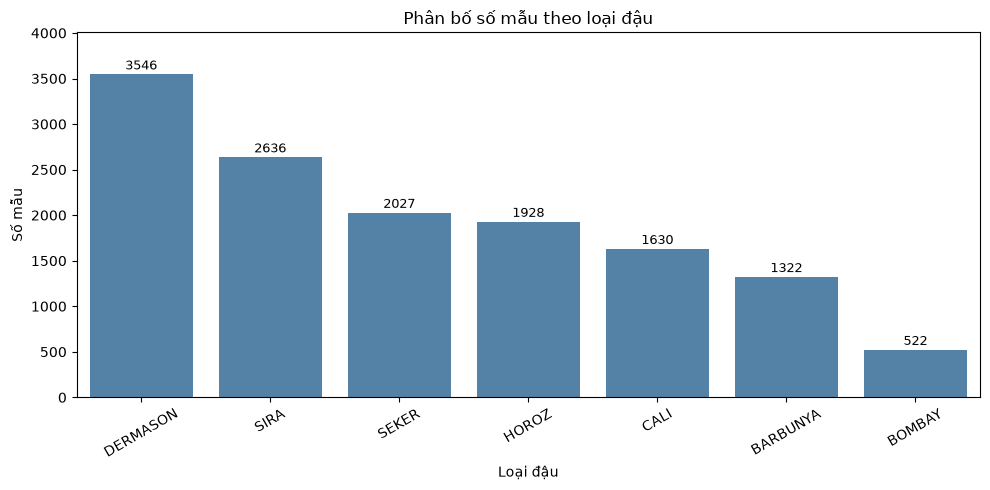

In [8]:
# DATA-06: Biểu đồ phân bố 7 lớp

fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(
    x=class_counts.index,
    y=class_counts.values,
    color="steelblue",
    ax=ax
)

for i, count in enumerate(class_counts.values):
    ax.text(
        i,
        count + class_counts.max() * 0.015,
        str(count),
        ha="center",
        fontsize=9
    )

ax.set_ylim(0, class_counts.max() * 1.13)
ax.set_title("Phân bố số mẫu theo loại đậu")
ax.set_xlabel("Loại đậu")
ax.set_ylabel("Số mẫu")

plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### 4.1. Nhận xét biểu đồ phân bố lớp

Biểu đồ cho thấy bộ dữ liệu Dry Bean gồm 7 loại đậu với số lượng mẫu không đồng đều. Trong đó, **DERMASON có nhiều mẫu nhất (3.546 mẫu, khoảng 26,05%)**, còn **BOMBAY có ít mẫu nhất (522 mẫu, khoảng 3,84%)**.

Số mẫu của lớp lớn nhất gấp khoảng **6,79 lần** lớp nhỏ nhất, cho thấy dữ liệu có sự mất cân bằng về số lượng giữa các lớp.

**Ý nghĩa:** Sự chênh lệch này có thể khiến mô hình phân lớp ưu tiên những lớp có nhiều mẫu. Vì vậy, nhóm cần sử dụng phương pháp đánh giá phù hợp như **Stratified K-Fold và F1-macro** để xem xét hiệu quả trên tất cả các lớp, thay vì chỉ dựa vào Accuracy.

**Kết luận:** Phân bố nhãn không đồng đều là đặc điểm cần lưu ý khi xây dựng và đánh giá các mô hình phân lớp.


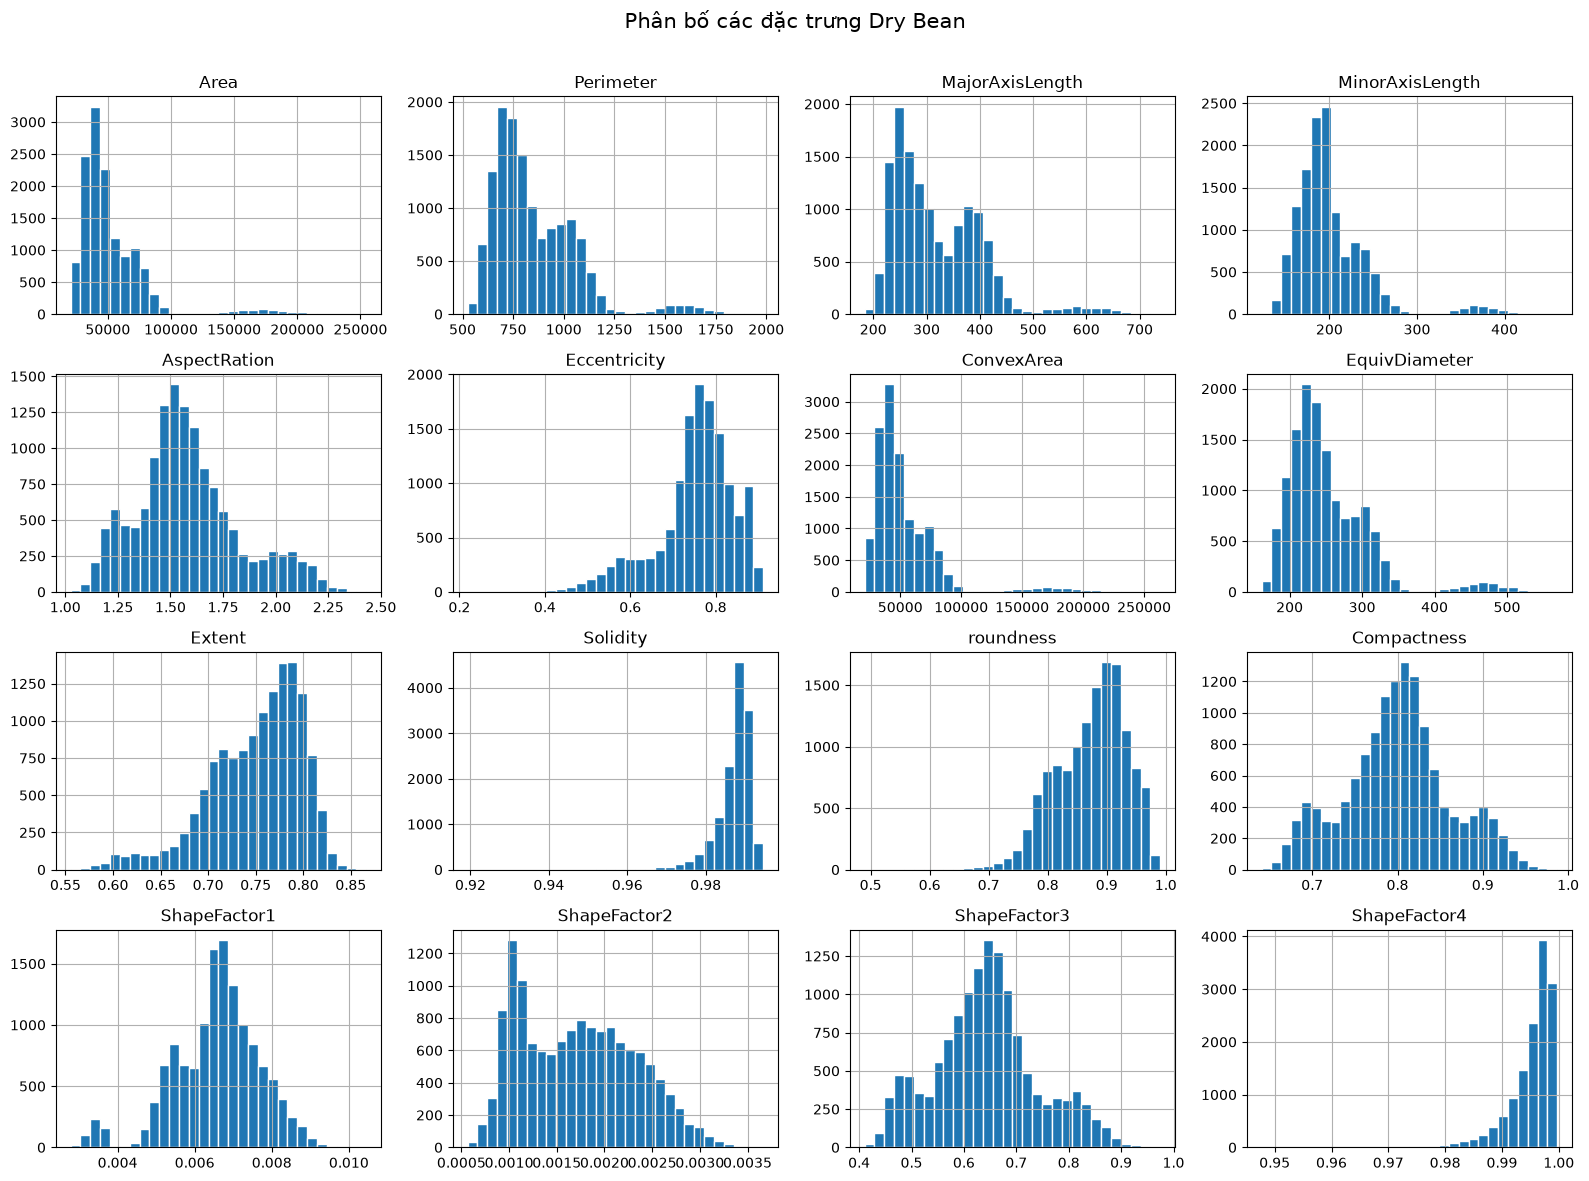

In [9]:
# DATA-06: Histogram các đặc trưng

axes = numeric_features.hist(
    bins=30,
    figsize=(16, 12),
    edgecolor="white"
)

fig = axes.flat[0].figure

fig.suptitle(
    "Phân bố các đặc trưng Dry Bean",
    fontsize=15
)

fig.tight_layout(rect=(0, 0, 1, 0.97))

fig.savefig(
    FIGURES_DIR / "histograms.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### 4.2. Nhận xét biểu đồ Histogram

Các histogram thể hiện sự khác biệt về phân bố giá trị giữa 16 đặc trưng hình thái của hạt đậu.

- **Nhóm đặc trưng kích thước:** Các thuộc tính như `Area`, `Perimeter`, `MajorAxisLength` và `ConvexArea` có phạm vi giá trị rộng, phản ánh sự khác biệt về kích thước giữa các mẫu.
- **Nhóm đặc trưng hình dạng:** Các thuộc tính như `Eccentricity`, `Roundness`, `Compactness` và `ShapeFactor1` có thang đo khác với nhóm kích thước.
- **Hình dạng phân bố:** Một số histogram có thể xuất hiện phân bố lệch hoặc nhiều vùng tập trung giá trị. Đây là dấu hiệu cần khảo sát thêm theo từng lớp đậu, chưa đủ để kết luận nguyên nhân.

**Ý nghĩa:** Sự khác biệt về thang đo cho thấy cần cân nhắc chuẩn hóa dữ liệu trước khi áp dụng PCA và các thuật toán phụ thuộc vào khoảng cách.

**Kết luận:** Histogram cung cấp cái nhìn tổng quan về phân bố đặc trưng, hỗ trợ lựa chọn phương pháp tiền xử lý phù hợp.


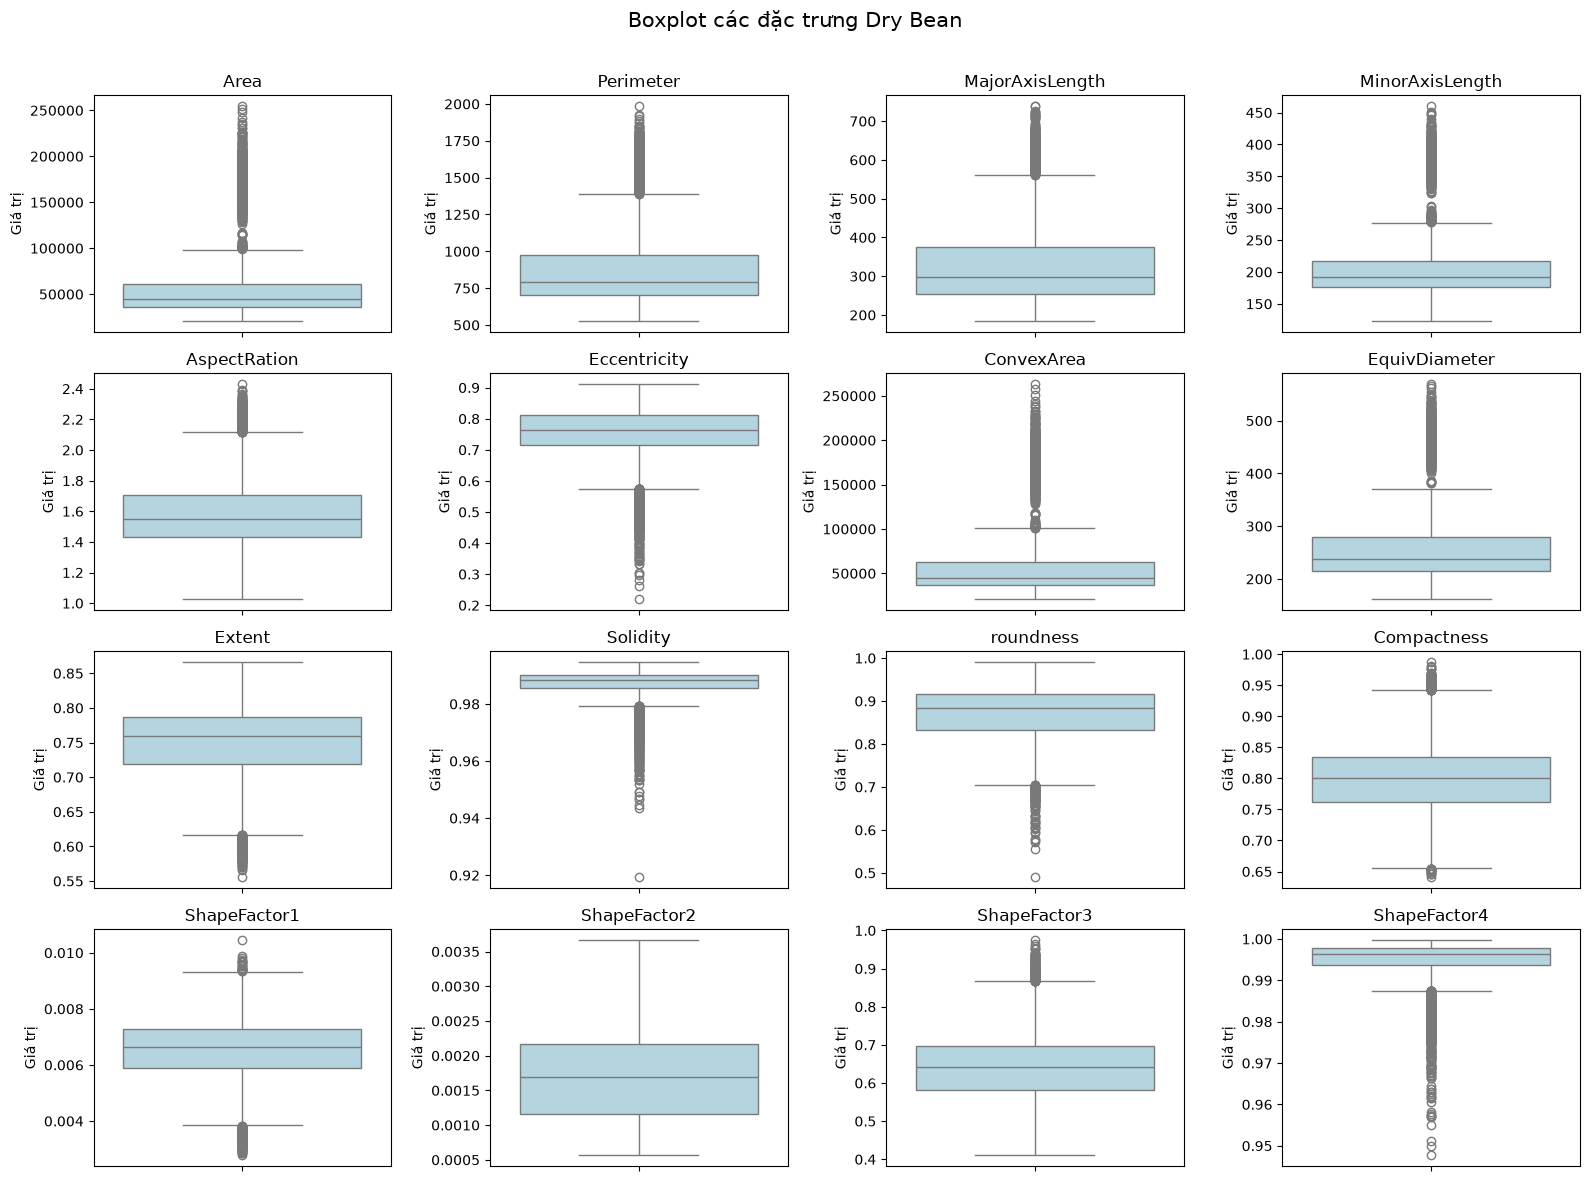

In [10]:
# DATA-06: Boxplot 16 đặc trưng

fig, axes = plt.subplots(
    4, 4,
    figsize=(16, 12)
)

for ax, col in zip(
    axes.flat,
    numeric_features.columns
):
    sns.boxplot(
        y=numeric_features[col],
        ax=ax,
        color="lightblue"
    )
    ax.set_title(col)
    ax.set_ylabel("Giá trị")

fig.suptitle(
    "Boxplot các đặc trưng Dry Bean",
    fontsize=15
)

fig.tight_layout(rect=(0, 0, 1, 0.97))

fig.savefig(
    FIGURES_DIR / "boxplots.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### 4.3. Nhận xét biểu đồ Boxplot

Các boxplot cho thấy sự khác biệt về trung vị, khoảng tứ phân vị (IQR) và mức độ phân tán của 16 đặc trưng hình thái.

Một số thuộc tính xuất hiện các điểm nằm ngoài khoảng giới hạn của boxplot, cho thấy sự tồn tại của **ngoại lệ tiềm năng** theo quy tắc 1,5 × IQR.

Kết quả kiểm tra IQR cho thấy có **3.017 dòng chứa ít nhất một giá trị ngoài ngưỡng**, tương đương khoảng **22,17% tổng số mẫu**. Đây là số dòng được đánh dấu, không phải số dòng chắc chắn bị lỗi.

**Ý nghĩa:** Các giá trị bất thường có thể xuất phát từ sự khác biệt tự nhiên về kích thước và hình dạng giữa các loại đậu. Nếu loại bỏ hàng loạt, dữ liệu có nguy cơ mất những mẫu hợp lệ và làm thay đổi phân bố lớp.

**Kết luận:** Trong phạm vi EDA, nhóm chỉ ghi nhận ngoại lệ và giữ nguyên dữ liệu gốc. Việc xử lý sẽ được xem xét trước khi xây dựng mô hình.


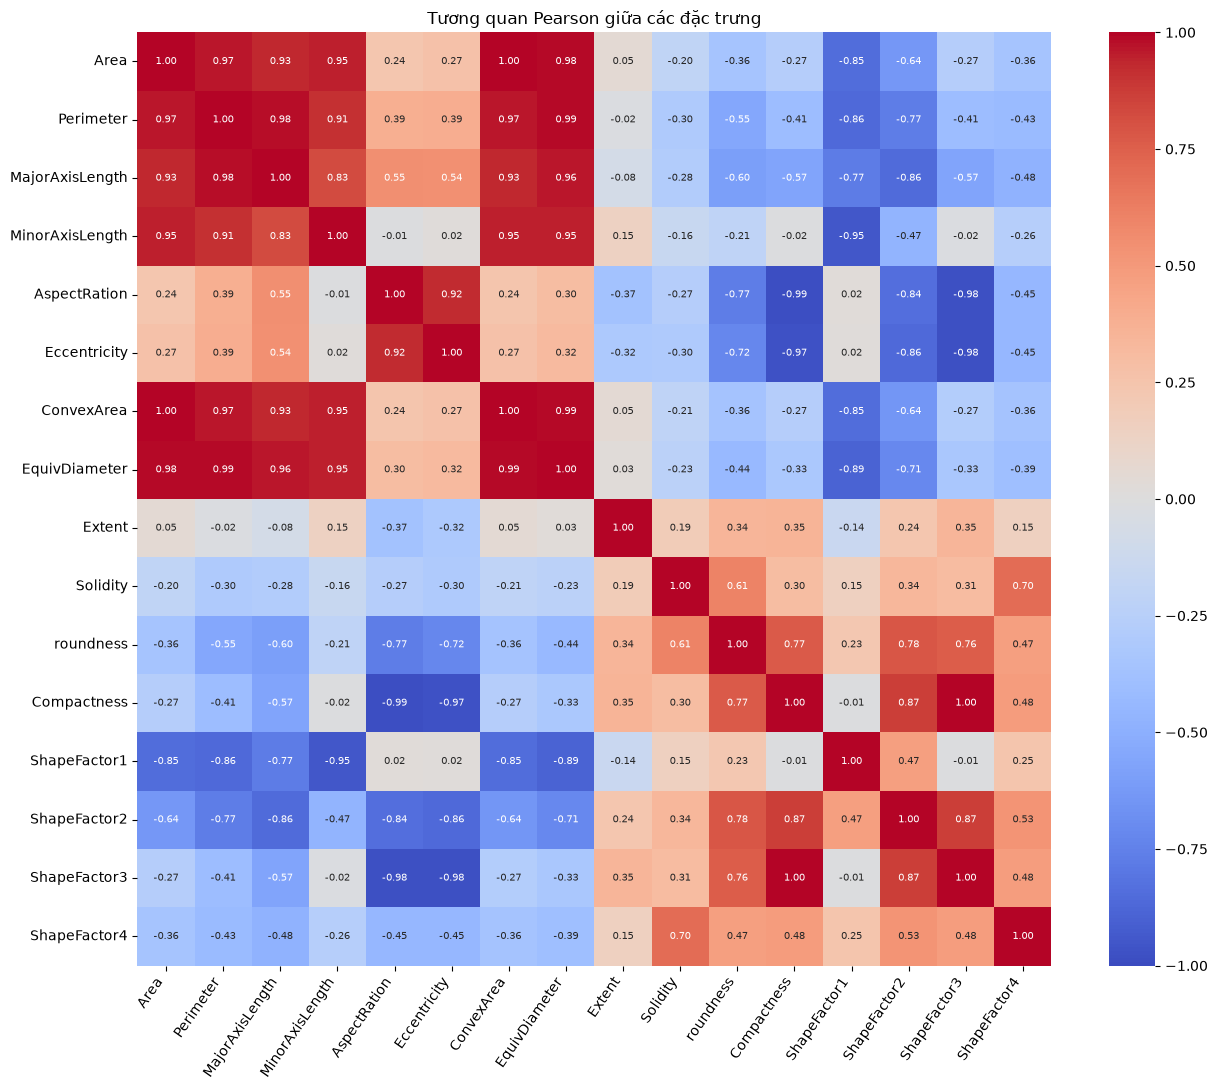

In [11]:
# DATA-06: Ma trận tương quan Pearson

corr = numeric_features.corr(
    method="pearson"
)

fig, ax = plt.subplots(figsize=(13, 11))

sns.heatmap(
    corr,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 7},
    ax=ax
)

ax.set_title("Tương quan Pearson giữa các đặc trưng")

plt.xticks(rotation=55, ha="right")
plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [12]:
# DATA-07: Tìm các cặp tương quan mạnh nhất

upper = corr.where(
    np.triu(
        np.ones(corr.shape, dtype=bool),
        k=1
    )
)

pairs = upper.stack().reset_index()

pairs.columns = [
    "Đặc trưng 1",
    "Đặc trưng 2",
    "Pearson r"
]

pairs["|r|"] = pairs["Pearson r"].abs()

pairs = pairs.sort_values(
    "|r|",
    ascending=False
)

print("5 cặp đặc trưng tương quan mạnh nhất:")
display(pairs.head(5))

pairs.to_csv(
    TABLES_DIR / "correlation_pairs.csv",
    index=False,
    encoding="utf-8-sig"
)


5 cặp đặc trưng tương quan mạnh nhất:


,Đặc trưng 1,Đặc trưng 2,Pearson r,|r|
6,Area,ConvexArea,0.999939,0.999939
190,Compactness,ShapeFactor3,0.998686,0.998686
23,Perimeter,EquivDiameter,0.991380,0.991380
75,AspectRation,Compactness,-0.987687,0.987687
103,ConvexArea,EquivDiameter,0.985226,0.985226


### 4.4. Nhận xét biểu đồ Heatmap Pearson

Heatmap cho thấy nhiều đặc trưng hình thái của bộ dữ liệu Dry Bean có tương quan tuyến tính mạnh.

- **Area và ConvexArea:** Tương quan dương rất mạnh (r ≈ 0,9999), cho thấy hai thuộc tính diện tích biến thiên gần như cùng chiều.
- **Compactness và ShapeFactor3:** Tương quan dương rất mạnh (r ≈ 0,9987).
- **Perimeter và EquivDiameter:** Tương quan dương mạnh (r ≈ 0,9914).
- **AspectRation và Compactness:** Tương quan âm mạnh (r ≈ -0,9877), thể hiện xu hướng biến thiên ngược chiều.

**Ý nghĩa:** Các cặp tương quan cao cho thấy dữ liệu có khả năng chứa thông tin chồng lặp giữa các đặc trưng. Đây là cơ sở để nhóm xem xét phương pháp PCA nhằm giảm số chiều dữ liệu.

**Kết luận:** Tương quan Pearson giúp xác định quan hệ tuyến tính giữa các thuộc tính nhưng không đủ để quyết định loại bỏ đặc trưng hoặc đánh giá khả năng dự đoán của chúng.


## Kết luận EDA

Qua quá trình khám phá dữ liệu, bộ Dry Bean gồm 13.611 mẫu, 16 đặc trưng số và 7 lớp phân loại. Dữ liệu không có giá trị thiếu nhưng tồn tại 68 bản ghi trùng hoàn toàn và các ngoại lệ tiềm năng theo phương pháp IQR.

Kết quả trực quan hóa cho thấy số mẫu giữa các lớp không đồng đều, các đặc trưng có thang đo khác nhau và một số thuộc tính có tương quan tuyến tính mạnh.

**Đề xuất cho các bước tiếp theo:**
- Cân nhắc chuẩn hóa đặc trưng trước khi thực hiện PCA và các thuật toán phụ thuộc khoảng cách.
- Sử dụng Stratified K-Fold và F1-macro khi đánh giá mô hình phân lớp.
- Xem xét phương án xử lý bản ghi trùng và ngoại lệ trước khi huấn luyện mô hình.

**Kết luận:** Kết quả EDA cung cấp cơ sở cho các thành viên tiếp tục thực hiện PCA, phân lớp và gom cụm. Trong giai đoạn này, dữ liệu gốc được giữ nguyên để bảo đảm khả năng đối chiếu và tái lập kết quả.


## Bàn giao và kiểm tra

- [x] Đọc dữ liệu Excel và chuyển sang CSV.
- [x] Kiểm tra tính toàn vẹn sau chuyển đổi.
- [x] Khảo sát cấu trúc và kiểu dữ liệu.
- [x] Thống kê phân bố 7 lớp.
- [x] Tính Min, Max và Mean của 16 đặc trưng.
- [x] Kiểm tra Missing, Duplicate và ngoại lệ IQR.
- [x] Trực quan hóa bằng 4 loại biểu đồ.
- [x] Viết nhận xét và kết luận EDA.
- [ ] Chạy lại toàn bộ Notebook từ đầu.
- [ ] Kiểm tra các file đầu ra trong `outputs/`.
- [ ] Push lên nhánh `lan-brand` và tạo Pull Request.

**Nguồn dữ liệu:** UCI Machine Learning Repository – Dry Bean Dataset.

https://archive.ics.uci.edu/dataset/602/dry+bean+dataset
